> **You are running this notebook in your browser.** Your changes are saved in this browser only. At the end of class, choose **File → Download** to keep a copy of your work.

In [ ]:
# Browser setup (added automatically): installs plotting support and lets the notebook load data from the web.
%pip install -q seaborn pyodide-http
import pyodide_http
pyodide_http.patch_all()


# Welcome to Talking Trees Day 6!

We've covered a lot of ground! So far, we've looked at how the environment changes over the course of a day, throughout the year, and between a normal and a drought year. We've also looked at how the xylem and stomata anatomy of Erisma and Itauba compare to other species in the Amazon. It's time to put it all together to solve the mystery of which tree will survive drought and which will fall apart.

Take a few minutes to review the key takeways from the previous modules and the lectures.


Today, we'll be looking at how well Erisma and Itabua recovered from drought.

---

As always, let's first run our setup.

In [1]:
# DO NOT EDIT THIS BLOCK

# @title Run Setup

# Load in the packages/libraries
# Packages and libraries contain functions which will perform certain actions in code
import hashlib
import pandas as pd # to manipulate data
import numpy as np # for mathematical operations
from cycler import cycler
import matplotlib.pyplot as plt # for plotting
import seaborn as sns # for plotting




# Define environmental variables
env_vars = ['temp', 'light', 'rain', 'humidity']

# Define a consistent color palette for variables
variable_colors = {
    'temp': '#a6cee3',
    'light': '#1f78b4',
    'rain': '#b2df8a',
    'humidity': '#33a02c',
    'VPD' : '#fdbf6f',
    'sf.itauba': '#fb9a99',
    'sf.erisma': '#e31a1c',
    'Itauba' : '#fb9a99',
    'Erisma' : '#e31a1c',
    'Other species' : '#fdbf6f'
}





# Load in the custom functions

## Create a function to load in data without worrying about file paths

# Load data directly into Python (into RAM) from public download link.
# - You need to turn the share link that looks like this: https://drive.google.com/file/d/FILE_ID/view?usp=sharing
#   -- ...into a download link that looks like this: https://drive.google.com/uc?export=download&id=FILE_ID
#   -- I.e. start with https://drive.google.com/ , add uc?export=download&id= , then the share-link text between "/d/" and "/view?" (here "FILE_ID").
# Dataset share link: https://drive.google.com/file/d/1GenDfhfqKDPM_AcG8eJyrzOxDuMz7vTL/view?usp=drive_link
# Dataset download URL


def load_data(dataset):
  if dataset == "environment_data_subset":
    url = 'https://lawrence-hall-of-science.github.io/talking-trees/data/Sapflow_HalfHourly_TTMods_V1.0.csv'
    df = pd.read_csv(url)
    # select only the columns we want to use
    cols = ['date', 'year', 'month', 'hour', 'temp', 'light', 'rain', 'humidity', 'yr.label']
    data_temp = df[cols]
    print("Data Loaded Successfully")
    print(len(data_temp), " rows of data loaded")
    return df[cols]

  elif dataset == "environment_sapflow_data_subset":
    url = 'https://lawrence-hall-of-science.github.io/talking-trees/data/Sapflow_HalfHourly_TTMods_V1.0.csv'
    df = pd.read_csv(url)
    # select only the columns we want to use
    cols = ['date', 'year', 'month', 'hour', 'temp', 'light', 'rain', 'humidity', 'yr.label', 'sf.itauba', 'sf.erisma']
    data_temp = df[cols]
    print("Data Loaded Successfully")
    print(len(data_temp), " rows of data loaded")
    return df[cols]

  elif dataset == "environment_sapflow_data_all":
    url = 'https://lawrence-hall-of-science.github.io/talking-trees/data/Sapflow_HalfHourly_TTMods_V1.0.csv'
    df = pd.read_csv(url)
    # select only the columns we want to use
    cols = ['date', 'year', 'month', 'hour', 'temp', 'light', 'rain', 'VPD', 'humidity', 'yr.label', 'sf.itauba', 'sf.erisma']
    data_temp = df[cols]
    print("Data Loaded Successfully")
    print(len(data_temp), " rows of data loaded")
    return df[cols]

  elif dataset == "stomata_data":
    url = "https://lawrence-hall-of-science.github.io/talking-trees/data/Stomata_Species_prc-250602.csv"
    df = pd.read_csv(url)
    # rename the columns
    df = df[['fam.scr', 'gen.scr', 'sp.scr', 'st.length', 'st.dens']].copy()
    df.rename(columns = {'fam.scr': 'family', 'gen.scr': 'genus', 'sp.scr': 'species'}, inplace = True)
    # Make a 'species category' column
    df['species_category'] = df['species'].apply(lambda x: 'Erisma' if x == 'Erisma uncinatum' else 'Itauba' if x == 'Mezilaurus itauba' else 'Other species')
    # Convert mm to m
    df['st.length'] = df['st.length']/1000
    df['st.dens'] = df['st.dens']*1000*1000
    data_temp = df
    print("Data Loaded Successfully")
    print(len(data_temp), " rows of data loaded")
    return df

  elif dataset == "xylem_data":
    url = 'https://lawrence-hall-of-science.github.io/talking-trees/data/Xylem_Species_prc-240216.csv'
    df = pd.read_csv(url)
    df = df[['fam.scr', 'gen.scr', 'sp.scr', 'diam.avg', 'area.avg', 'diam.max', 'ves.dens', 'rel.lum.area']].copy()
    df.rename(columns = {'fam.scr': 'family', 'gen.scr': 'genus', 'sp.scr': 'species'}, inplace = True)
    df['species_category'] = df['species'].apply(lambda x: 'Erisma' if x == 'Erisma uncinatum' else 'Itauba' if x == 'Mezilaurus itauba' else 'Other species')
    data_temp = df
    print("Data Loaded Successfully")
    print(len(data_temp), " rows of data loaded")
    return df

  else:
    print("Dataset not found. Please input a valid dataset name.")

  data = df[cols]
  print("Data Loaded Successfully")
  print(len(data), " rows of data loaded")
  return data


## Function to the the monthly summary for environmental data
def get_monthly_summary(data, vars = env_vars) :

  cols = ['year', 'month', 'hour'] + vars
  data = data[cols]

  if 'rain' in data.columns:
    # Do rain first since it doesn't get filtered to daytime values
    dat_mo = data.groupby(['year', 'month'])['rain'].sum().reset_index()

  # isolate daytime values for everything except for rain
  idl = (data['hour'] > 9) & (data['hour'] < 17)

  if 'rain' in data.columns:
    vars = [v for v in vars if v != "rain"] # make sure it's all the variables but rain

  # Group the data so we get averages for each month in each year separately
  dat_mo2 = data.loc[idl].groupby(['year', 'month'])[vars].mean().reset_index()

  # Put rain and the other variables back together in the same table
  if 'rain' in data.columns:
    dat_mo_combo = pd.merge(dat_mo, dat_mo2, how = "right", on = ["year", "month"])
  else:
    dat_mo_combo = dat_mo2


  # Add in the labels for drought condition for each year -- may not need if this column is already in the dataset
  dat_mo_combo['yr_label'] = 'Normal'
  dat_mo_combo.loc[dat_mo_combo['year'] == 2015, 'yr_label'] = 'Drought'
  dat_mo_combo.loc[dat_mo_combo['year'] == 2016, 'yr_label'] = 'Post-Drought'

  return dat_mo_combo


# Plotting function for monthly trends across years
def plot_monthly_data(data, vars = env_vars, years = ['Normal'], xaxis = 'month'):

  # Make our basic plot, with enough subplots for each variable
  fig, axs = plt.subplots(len(vars), 1, sharex=True, figsize=(6, 8))

  # Loop through variables to create plots - this will make one subplot for each variable we put into it
  for i, var in enumerate(vars):
    # Make a title for each plot
      title = f"Monthly average of {var} over the course of a year"
      axs[i].set_title(title)
      # Make a lineplot for each variable, for each year
      sns.lineplot(ax = axs[i], x = xaxis, y = var, data = data[data['yr_label'].isin(years)], hue = "yr_label", legend = True)
      # Add points to each graph
      sns.scatterplot(ax = axs[i], x = xaxis, y = var, data = data[data['yr_label'].isin(years)], hue = "yr_label", legend = False)
      # Shade the wet season
      axs[i].axvspan(1, 7, facecolor = "grey", alpha = 0.2)

  # Create a proxy artist for the wet season label
  wet_season_patch = plt.matplotlib.patches.Rectangle((0,0), 1, 1, facecolor="grey", alpha=0.2, label='Wet Season')

  # Apply a common legend
  handles, labels = axs[0].get_legend_handles_labels()  # Get legend from first plot
  custom_labels = years
  handles.append(wet_season_patch) # Add the wet season patch to the handles
  custom_labels.append('Wet Season') # Add the wet season label

  fig.legend(handles, custom_labels, loc = 'right', title = "Year", bbox_to_anchor = (1.3, 0.5)) # set it on the right side
  for i, fig in enumerate(vars):
    axs[i].get_legend().remove() # Remove the legends from each individual plot
  plt.tight_layout()  # Adjust layout to prevent overlap
  plt.show()



# Function to plot N random days of diurnal data

def graph_diurnals(data, n_days = 6, vars = ['temp', 'light'], title = '') :

  # Subset data and order factor levels to plot in order specificed in env_vars
  # Make sure vars is in the right format

  # Prepare the data for plotting
  # Select all the columns we want
  cols = ['date', 'hour', 'month'] + vars + ['sf.erisma', 'sf.itauba']
  # Pick dates from 2014
  dat_d = pd.melt(data[data['year'] == 2014][cols], id_vars = ['date', 'hour', 'month'])
  dat_d['variable'] = dat_d['variable'].astype('category')
  # Remove all the nighttime data
  dat_final = dat_d[(dat_d['hour'] >= 5) & (dat_d['hour'] <= 20)]

  # Ensure the variables we want to plot are actually in the dat_d dataframe columns
  # This prevents errors if a variable name is mistyped or not present
  valid_vars = [v for v in vars if v in dat_final['variable'].unique()] + ['sf.erisma', 'sf.itauba']
  sub = dat_final[dat_final['variable'].isin(valid_vars)].copy()
  if sub.empty:
      print("Error: No data available for the specified variables and dates.")
      return # Exit the function if there's no data to plot

  # Add a column for the wet and dry season
  sub['season'] = 'dry'
  sub.loc[(sub['month'] >= 1) & (sub['month'] <= 7), 'season'] = 'wet'


  # Pick a random sample of days from the chosen year
  # Half will be from the wet season and half from the dry season
  sub['variable'] = pd.Categorical(sub['variable'], categories = valid_vars)
  sub_wet = sub[sub['season'] == 'wet']
  sub_dry = sub[sub['season'] == 'dry']
  unique_dates_wet = sub_wet['date'].unique()
  unique_dates_dry = sub_dry['date'].unique()
  n_days_dry = round(n_days/2)
  n_days_wet = n_days - n_days_dry
  sampled_dates_wet = np.random.choice(unique_dates_wet, size= n_days_wet, replace=False)
  sampled_dates_dry = np.random.choice(unique_dates_dry, size= n_days_dry, replace=False)
  sub_sampled_days_wet = sub[sub['date'].isin(sampled_dates_wet)].copy()
  sub_sampled_days_dry = sub[sub['date'].isin(sampled_dates_dry)].copy()
  # Ensure sub_sampled_days only contains the selected dates and variables
  sub_sampled_days_wet = sub_sampled_days_wet[sub_sampled_days_wet['variable'].isin(valid_vars)]
  sub_sampled_days_dry = sub_sampled_days_dry[sub_sampled_days_dry['variable'].isin(valid_vars)]
  # Merge the wet and the dry back together
  sub_sampled_days = pd.concat([sub_sampled_days_wet, sub_sampled_days_dry])

  # Determine the layout of the subplots: columns = dates, rows = variables

  # Separate the sf.itauba and sf.erisma variables to plot them together
  sf_vars = ['sf.itauba', 'sf.erisma']
  other_vars = [v for v in valid_vars if v not in sf_vars]
  plot_vars = other_vars + ['sapflow'] # Add a placeholder for the combined sapflow plot

  n_cols = len(sub_sampled_days['date'].unique())
  n_rows = len(plot_vars)
  fig, axs = plt.subplots(n_rows, n_cols, sharex=True, figsize=(12, 10))

  # Ensure all the y axes are on the same scale per varaible
  # Make this the same for all days, not just the ones selected
  y_limits = {
    var: (
      dat_final[dat_final['variable'] == var]['value'].min(),
      dat_final[dat_final['variable'] == var]['value'].max()
    )
    for var in valid_vars
  }

  # Make plots for each varable-date combination
  for i, var in enumerate(plot_vars):
    for j, date in enumerate(sub_sampled_days['date'].unique()):
      ax = axs[i,j]
      if var == 'sapflow':
          subset = sub_sampled_days[(sub_sampled_days['date'] == date) & (sub_sampled_days['variable'].isin(sf_vars))]
          sns.lineplot(data=subset, x='hour', y='value', ax=ax, hue='variable', legend=False, palette=variable_colors) # Remove legend from subplot
          # Set y-axis limits for sapflow variables
          min_sf = min(y_limits['sf.itauba'][0], y_limits['sf.erisma'][0])
          max_sf = max(y_limits['sf.itauba'][1], y_limits['sf.erisma'][1])
          ax.set_ylim(min_sf, max_sf)
      else:
          subset = sub_sampled_days[(sub_sampled_days['date'] == date) & (sub_sampled_days['variable'] == var)]
          sns.lineplot(data=subset, x = 'hour', y = 'value', ax=ax, hue = 'variable', legend = False, palette=variable_colors) # Remove legend from subplot
          ax.set_ylim(y_limits[var])

  # Set the axes labels
  for i, var in enumerate(plot_vars):
      label = 'Sapflow' if var == 'sapflow' else var
      axs[i, 0].set_ylabel(f'{label}', fontsize=12, rotation=0, labelpad=50)
  for j, date in enumerate(sub_sampled_days['date'].unique()):
    axs[0, j].set_title(f'{date}', fontsize=12, pad = 20)

  # Add a single legend for the entire figure
  # Get handles and labels for all variables
  all_handles = []
  all_labels = []
  for var in other_vars:
      # Create a proxy artist for each individual variable
      all_handles.append(plt.Line2D([0], [0], color=variable_colors[var], lw=2))
      all_labels.append(var)

  # Create proxy artists for the sapflow variables
  for sf_var in sf_vars:
      all_handles.append(plt.Line2D([0], [0], color=variable_colors[sf_var], lw=2))
      all_labels.append(sf_var)

  fig.legend(all_handles, all_labels, loc='right', title='Variable', bbox_to_anchor=(1.2, 0.5))

  plt.tight_layout()
  plt.show()


## Custom function for calculating the stomatal conductive capacity
def calc_gw_max(data, length = 'st.length', density = 'st.dens') :
    length = data[length]
    density = data[density]
    pi = 3.14159265359
    d = 0.0000249
    v = 0.0224
    A = 0.12 * length * length/2
    l = length/4
    gw_max = (d * (density/v)) * (A / (l + (0.5 * ((pi * A)**0.5))))
    return gw_max



print("Setup Run Correctly!")


Setup Run Correctly!


Now, let's load in our dataset. We'll be using the 'environment_sapflow_data_all' dataset. Save it as an object called 'sapflow' and look at the first five rows.

In [2]:
#### This block will only have the comments for students

# Load in the data
sapflow = load_data(dataset = 'environment_sapflow_data_all')

# Look at the first 5 rows of our table
sapflow.head(5)

Data Loaded Successfully
52608  rows of data loaded


,date,year,month,hour,temp,light,rain,VPD,humidity,yr.label,sf.itauba,sf.erisma
0,2014-01-01,2014,1,0.0,26.004257,0.0,0.0,0.435338,87.056423,Normal,0.028277,0.004453
1,2014-01-01,2014,1,0.5,25.535532,0.0,0.0,0.386602,88.227500,Normal,0.002067,0.001142
2,2014-01-01,2014,1,1.0,25.058028,0.0,0.0,0.328828,89.671820,Normal,0.001554,0.002101
3,2014-01-01,2014,1,1.5,24.662494,0.0,0.0,0.299472,90.368769,Normal,0.000345,0.002418
4,2014-01-01,2014,1,2.0,24.331351,0.0,0.0,0.276112,90.931979,Normal,0.000000,0.002712


You'll notice we have a new data column from last time, the VPD. Remember the VPD is ***however we're explaining it here***

Let's take another look at how the environment changes throughout the year using monthly summaries. We'll also add in the sapflow data.

In [3]:
# Pick the environmental variables you want to explore

env_vars = ['temp', 'light']

In [4]:
# Because we want to look at the sapflow data too, we'll have to add in the column names for sapflow
# As always, we put the names of columns in quotes

# Add in the sapflow data
all_vars = env_vars + ['sf.itauba', 'sf.erisma'] ###### am I supposed to use sf.itauba and sf.erisma here or sfhl.itauba ans sfhl.erisma?? The R code has sfhl but the first day uses sf.....
all_vars

['temp', 'light', 'rain', 'VPD', 'sf.itauba', 'sf.erisma']

Great! This will tell the function to choose the environmental columns, **and** the sapflow data. Now let's calculate the monthly averages using *get_monthly_summary()*. The arguments are the data table (*data*) and the variables we want to use (*vars*). Save as an object called **sapflow_month**.

In [5]:
#### this code block only contain comments for students

# Calcluate the monthly averages
sapflow_month = get_monthly_summary(data = sapflow, vars = all_vars)

# Look at the first ten rows
sapflow_month.head(10)

,year,month,rain,temp,light,VPD,sf.itauba,sf.erisma,yr_label
0,2014,1,547.021024,28.103090,493.588596,1.165948,0.354478,0.152802,Normal
1,2014,2,1377.887204,27.110868,440.774309,0.940207,0.328124,0.185211,Normal
2,2014,3,999.515369,27.753086,487.716796,0.913870,0.350772,0.276677,Normal
3,2014,4,1117.979475,27.338733,390.823139,1.044146,0.312064,0.308711,Normal
4,2014,5,667.092511,28.114607,396.469541,1.165148,0.343280,0.323869,Normal
5,2014,6,407.784890,29.221922,481.586004,1.281522,0.366111,0.346916,Normal
6,2014,7,334.595286,29.235067,478.710313,1.249708,0.382737,0.339460,Normal
7,2014,8,157.028407,30.684951,626.672052,1.556525,0.403695,0.355897,Normal
8,2014,9,308.683940,30.187172,515.472235,1.496241,0.384640,0.274591,Normal
9,2014,10,23.870902,31.288328,630.798337,1.887548,0.429616,0.216541,Normal


Now, let's plot them!

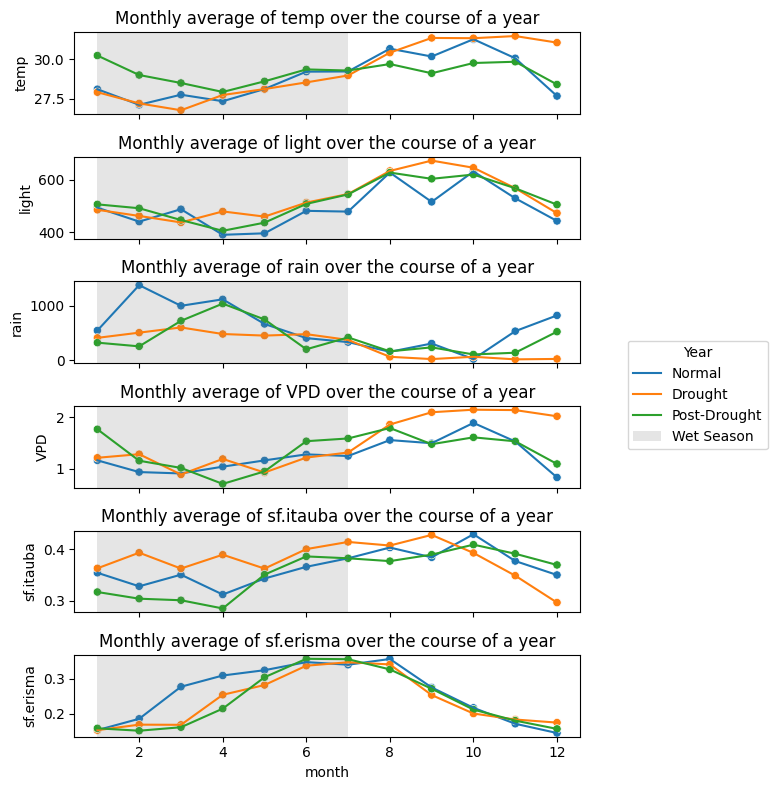

In [7]:
# Use the function plot_monthly_data() to make the graphs. The arguments are the data (data),
# the variables (vars), and the years to look at (years). For now, type ['Normal'] into
# the year argument.

#### This code block blank except for comments for students

plot_monthly_data(data = sapflow_month, vars = all_vars, years = ['Normal','Drought', 'Post-Drought'])

Once you've refreshed yourself on what a 'Normal' year looks like, edit the code above to look at both a Normal and Drought year. What do you notice? How do the trees react to drought?

Now add in the Post-Drought year. What do you notice? How well do the trees recover from drought?

Feel free to edit env_vars to look at other environmental variables!

***learning questions here***